# 01 · Veri İnceleme: MVTec AD `metal_nut`

Bu defterin amacı, yöntemleri geliştirmeden önce veriyi tanımaktır (CRISP-DM'in "veriyi anlama" aşaması):

1. Kaç görüntü var, kusur türleri nasıl dağılıyor?
2. Kusurlar görüntüde nasıl görünüyor, referans maskeler neyi işaretliyor?
3. Kusurlu bölgeler ne kadar büyük?
4. Görüntüler arasında konum/aydınlatma farkı var mı?

Veri kaynağı: MVTec AD (Bergmann vd., 2019), CC BY-NC-SA 4.0.

In [1]:
import sys
from pathlib import Path

PROJE = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJE))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.dataset import ornekleri_listele, goruntu_oku, maske_oku

SONUC = PROJE / "results" / "01_veri_inceleme"
SONUC.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 90
%config InlineBackend.figure_formats = ["jpeg"]

## 1. Görüntü sayıları

In [2]:
egitim = ornekleri_listele(bolum="train")
test = ornekleri_listele(bolum="test")

sayilar = pd.DataFrame([{"bolum": o.bolum, "kusur_turu": o.kusur_turu} for o in egitim + test])
tablo = sayilar.pivot_table(index="kusur_turu", columns="bolum", aggfunc="size", fill_value=0)
tablo.loc["TOPLAM"] = tablo.sum()
tablo

bolum,test,train
kusur_turu,,
bent,25,0
color,22,0
flip,23,0
good,22,220
scratch,23,0
TOPLAM,115,220


Eğitim bölümünde yalnızca sağlam görüntüler var. Test bölümünde 22 sağlam ve 93 kusurlu görüntü bulunuyor.
Klasik yöntemler eğitim gerektirmediği için eğitim görüntülerini **eşik değerlerini sağlam yüzeylere göre ayarlamak** için kullanabiliriz.

## 2. Her kusur türünden bir örnek

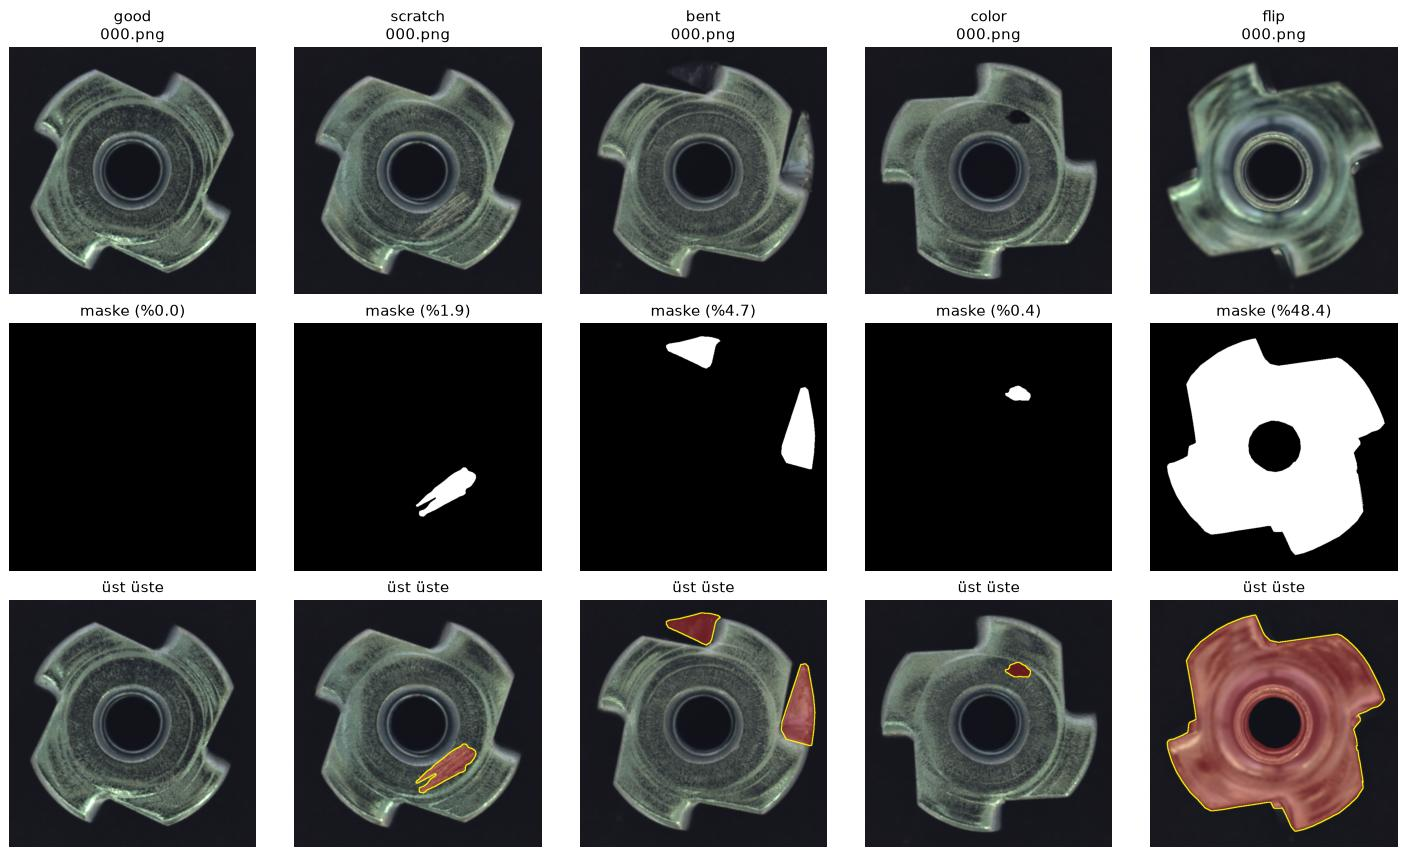

In [3]:
def maske_bindir(rgb, maske, renk=(255, 40, 40)):
    """Maskeyi yarı saydam renk ve kontur olarak görüntünün üzerine çizer."""
    cikti = rgb.copy()
    katman = cikti.copy()
    katman[maske] = renk
    cikti = cv2.addWeighted(katman, 0.35, cikti, 0.65, 0)
    konturlar, _ = cv2.findContours(maske.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(cikti, konturlar, -1, (255, 255, 0), 2)
    return cikti

turler = ["good", "scratch", "bent", "color", "flip"]
fig, eksenler = plt.subplots(3, len(turler), figsize=(3.2 * len(turler), 9.6))
for j, tur in enumerate(turler):
    ornek = next(o for o in test if o.kusur_turu == tur)
    rgb, maske = goruntu_oku(ornek), maske_oku(ornek)
    eksenler[0, j].imshow(rgb)
    eksenler[0, j].set_title(f"{tur}\n{ornek.goruntu_yolu.name}")
    eksenler[1, j].imshow(maske, cmap="gray")
    eksenler[1, j].set_title(f"maske (%{maske.mean() * 100:.1f})")
    eksenler[2, j].imshow(maske_bindir(rgb, maske))
    eksenler[2, j].set_title("üst üste")
for e in eksenler.ravel():
    e.axis("off")
plt.tight_layout()
plt.savefig(SONUC / "ornekler.png", bbox_inches="tight")
plt.show()

Daha fazla örnek görmek için her türden 4 görüntü:

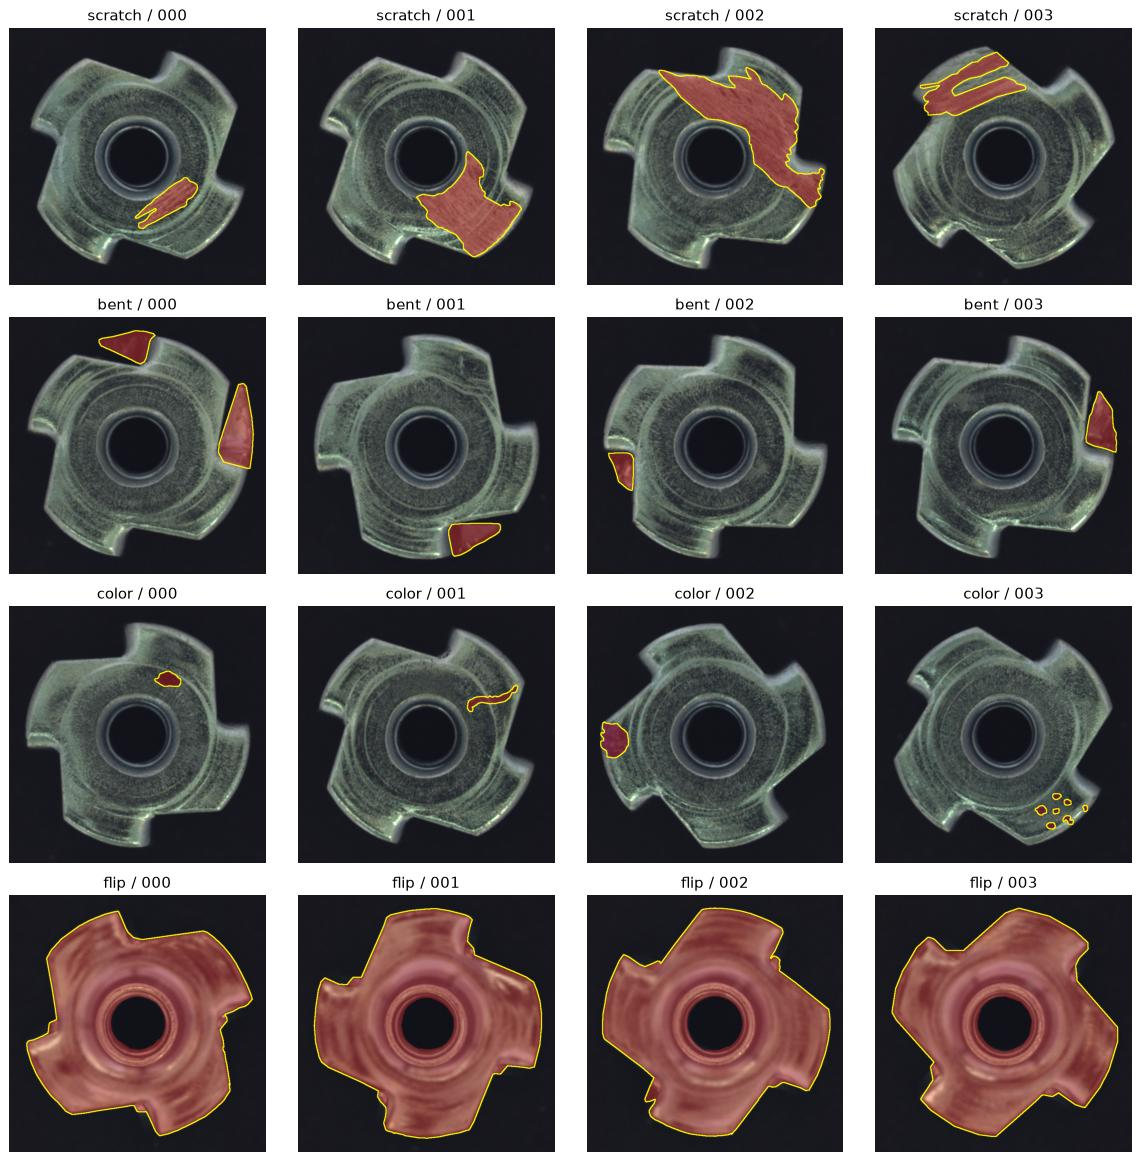

In [4]:
fig, eksenler = plt.subplots(len(turler) - 1, 4, figsize=(13, 13))
for i, tur in enumerate(turler[1:]):
    secilenler = [o for o in test if o.kusur_turu == tur][:4]
    for j, ornek in enumerate(secilenler):
        eksenler[i, j].imshow(maske_bindir(goruntu_oku(ornek), maske_oku(ornek)))
        eksenler[i, j].set_title(f"{tur} / {ornek.goruntu_yolu.stem}")
        eksenler[i, j].axis("off")
plt.tight_layout()
plt.savefig(SONUC / "turlere_gore_ornekler.png", bbox_inches="tight")
plt.show()

## 3. Kusurlu bölgelerin büyüklüğü

In [5]:
satirlar = []
for o in test:
    maske = maske_oku(o)
    bilesen_sayisi = cv2.connectedComponents(maske.astype(np.uint8))[0] - 1
    satirlar.append({"kusur_turu": o.kusur_turu, "alan_yuzde": maske.mean() * 100,
                     "bilesen_sayisi": bilesen_sayisi})
alanlar = pd.DataFrame(satirlar)
kusurlu = alanlar[alanlar.kusur_turu != "good"]

ozet = kusurlu.groupby("kusur_turu").agg(
    adet=("alan_yuzde", "size"),
    alan_min=("alan_yuzde", "min"),
    alan_medyan=("alan_yuzde", "median"),
    alan_max=("alan_yuzde", "max"),
    ort_bilesen=("bilesen_sayisi", "mean"),
).round(2)
ozet

,adet,alan_min,alan_medyan,alan_max,ort_bilesen
kusur_turu,,,,,
bent,25,0.71,1.87,4.70,1.40
color,22,0.44,2.09,6.57,1.36
flip,23,47.85,48.17,48.72,1.00
scratch,23,1.90,5.54,12.30,1.91


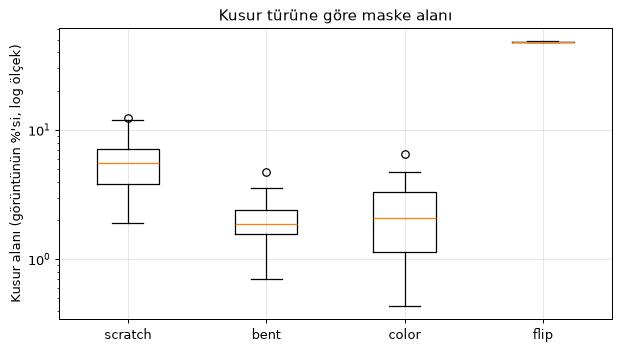

In [6]:
fig, eksen = plt.subplots(figsize=(7, 4))
sirali = ["scratch", "bent", "color", "flip"]
eksen.boxplot([kusurlu.loc[kusurlu.kusur_turu == t, "alan_yuzde"] for t in sirali], tick_labels=sirali)
eksen.set_yscale("log")
eksen.set_ylabel("Kusur alanı (görüntünün %'si, log ölçek)")
eksen.set_title("Kusur türüne göre maske alanı")
eksen.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SONUC / "kusur_alani.png", bbox_inches="tight")
plt.show()

## 4. Sağlam görüntüler birbirine ne kadar benziyor?

220 sağlam eğitim görüntüsünün ortalaması ve standart sapması hesaplanır.
Somunlar hep aynı konumda ve açıda duruyorsa ortalama görüntü keskin, standart sapma düşük olur.
Konum veya açı değişiyorsa ortalama bulanıklaşır ve standart sapma yükselir.

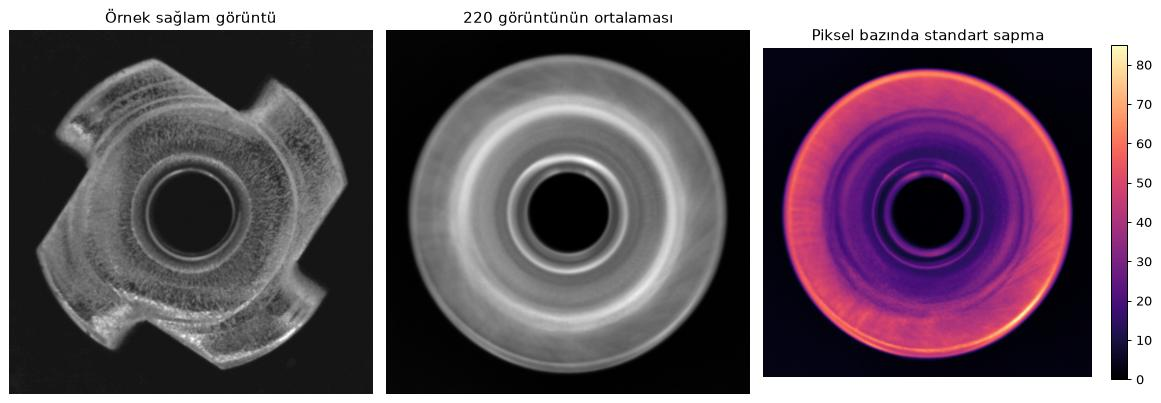

In [7]:
yigin = np.stack([goruntu_oku(o, gri=True).astype(np.float32) for o in egitim])
ortalama, sapma = yigin.mean(axis=0), yigin.std(axis=0)

fig, eksenler = plt.subplots(1, 3, figsize=(13, 4.5))
eksenler[0].imshow(goruntu_oku(egitim[0], gri=True), cmap="gray"); eksenler[0].set_title("Örnek sağlam görüntü")
eksenler[1].imshow(ortalama, cmap="gray"); eksenler[1].set_title("220 görüntünün ortalaması")
g = eksenler[2].imshow(sapma, cmap="magma"); eksenler[2].set_title("Piksel bazında standart sapma")
plt.colorbar(g, ax=eksenler[2], fraction=0.046)
for e in eksenler:
    e.axis("off")
plt.tight_layout()
plt.savefig(SONUC / "ortalama_sapma.png", bbox_inches="tight")
plt.show()

## 5. Parlaklık dağılımı ve somunu arka plandan ayırma

Gri seviye histogramı (ders: Piksel İşlemleri) ve Otsu eşiklemesiyle somunun arka plandan ne kadar kolay ayrıldığına bakılır.
Bu, kenar tespitinde somunun dış sınırlarını kusur sanmamak için gerekecek.

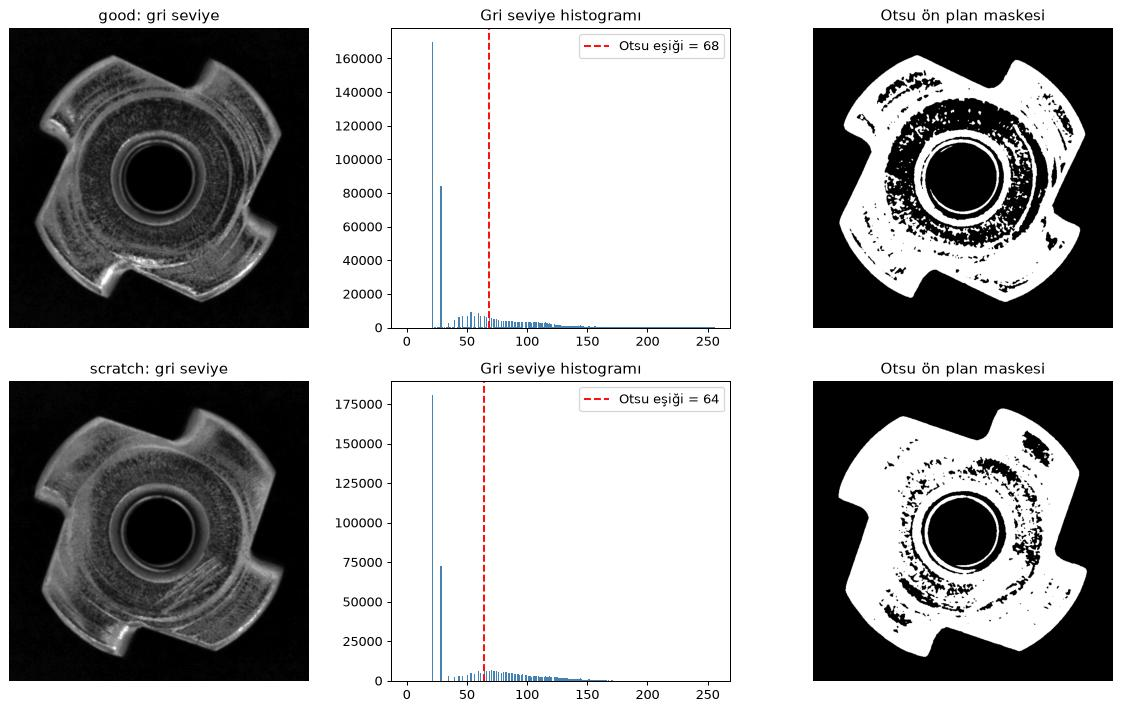

In [8]:
ornek_saglam = next(o for o in test if o.kusur_turu == "good")
ornek_cizik = next(o for o in test if o.kusur_turu == "scratch")

fig, eksenler = plt.subplots(2, 3, figsize=(13, 8))
for i, ornek in enumerate([ornek_saglam, ornek_cizik]):
    gri = goruntu_oku(ornek, gri=True)
    esik, on_plan = cv2.threshold(cv2.GaussianBlur(gri, (5, 5), 0), 0, 255,
                                  cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    eksenler[i, 0].imshow(gri, cmap="gray"); eksenler[i, 0].set_title(f"{ornek.kusur_turu}: gri seviye")
    eksenler[i, 1].hist(gri.ravel(), bins=256, range=(0, 256), color="steelblue")
    eksenler[i, 1].axvline(esik, color="red", ls="--", label=f"Otsu eşiği = {esik:.0f}")
    eksenler[i, 1].set_title("Gri seviye histogramı"); eksenler[i, 1].legend()
    eksenler[i, 2].imshow(on_plan, cmap="gray"); eksenler[i, 2].set_title("Otsu ön plan maskesi")
    eksenler[i, 0].axis("off"); eksenler[i, 2].axis("off")
plt.tight_layout()
plt.savefig(SONUC / "histogram_otsu.png", bbox_inches="tight")
plt.show()

## 6. Gözlemler ve yöntem planına etkileri

**1. Somunlar rastgele açılarla dönük.** Ortalama görüntü bir halka gibi bulanık çıkıyor; standart sapma en çok dış kenarda yüksek.
Bu yüzden "sağlam şablondan fark alma" yaklaşımı hizalama olmadan çalışmaz. Görüntüye tek tek bakan filtre tabanlı yöntemler (kenar, black-hat, Gabor) bu veri için daha uygun.

**2. Arka plan kolay ayrılıyor, ancak Otsu eşiği somunun koyu dokulu kısımlarını da kesiyor.**
Histogramda arka plan 20–30 civarında dar tepeler oluşturuyor. Otsu eşiği (~65) somunun koyu dokulu halkasını da arka plan sayıyor.
Somun maskesi (ROI) için daha düşük bir eşik, delik doldurma ve morfolojik kapama gerekecek.
Somunun dış sınırı ve ortadaki delik güçlü kenar ürettiği için kenar tespiti sonuçları bu maske ile sınırlandırılmalı.

**3. Yüzeyin kendisi çok dokulu.** Orta halkada ince taneli bir doku ve talaş izleri var.
Canny gibi kenar dedektörleri sağlam yüzeyde de çok sayıda kenar bulacak. Eşik ve yumuşatma ayarı kritik olacak; bilateral filtre burada denenmeli.

**4. Referans maskeler cömert çizilmiş.** Çizik maskeleri ince çizgileri değil, çiziklerin bulunduğu bölgenin tamamını kapsıyor (medyan alan görüntünün ~%5,5'i).
İnce çizgi bulan yöntemlerin piksel IoU'su bu yüzden doğal olarak düşük kalacak. Çizgileri bölgeye dönüştürmek (kapama/genişletme) ve
piksel ölçütlerinin yanında **bölge düzeyinde** bir ölçüt (tespit edilen bölge gerçek kusurla örtüşüyor mu?) raporlamak anlamlı olur.

**5. Kusur türleri çok farklı:**
| Tür | Görünüm | Klasik yöntemlerle beklenti |
|---|---|---|
| scratch | Belirli yönde ince paralel çizgiler | **Ana hedef.** Gabor / black-hat / kenar yöntemleri uygun |
| color | Küçük koyu veya renkli lekeler | Black-hat ile yakalanabilir; renk kanalları (Lab, HSV) yardımcı olabilir |
| bent | Kulakçık şekli bozulmuş, maske kısmen somunun dışında | Zor: şekil kusuru, yüzey filtresiyle bulunmaz |
| flip | Somun ters; maske tüm somunu kaplıyor | Piksel düzeyinde anlamsız; görüntü düzeyinde doku farkı (daha pürüzsüz yüzey) ile ayırt edilebilir |

Bu nedenle sonuçlar **kusur türüne göre ayrı ayrı** raporlanacak. `bent` ve `flip` türleri yöntemlerin sınırlarını gösteren örnekler olarak hata analizinde kullanılacak.